# Kats example: forecasting Tesla's closing price

- This notebook forecasts the next 30 trading days of Tesla's closing price with
  Kats, and checks how far the result can be trusted
- The data is the daily Tesla price history from 2010-07-01 to 2021-10-14,
  shipped in `data/TSLA.csv`
- The pedagogical arc:
  - Load the prices, put them on a regular business-day grid, and hand them to
    Kats
  - Define the problem: a chronological split, a baseline, and the metrics
  - Forecast with a naive baseline, ARIMA, and Prophet, and plot the forecasts
    with their prediction intervals
  - Score one test window, then repeat it on eight windows to see what holds up
  - Bonus: a trading-volume feature with `MLARModel`, other time intervals, and
    other stocks
- The Kats calls live in `kats_utils.py` and are introduced in `kats.API.ipynb`.
  This notebook orchestrates them

In [1]:
%load_ext autoreload
%autoreload 2

import logging
import os

# Kats warns at import time about optional packages (torch, ax-platform) that
# this notebook does not use. Raise the log level before importing it.
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)

import numpy as np
import pandas as pd

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import kats_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /home/claude/sim311/lib/python3.11/site-packages/ipykernel_launcher.py -f /tmp/tmprcn671iw.json --HistoryManager.hist_file=:memory:


# Part 1: From a price file to a Kats series

## Cell 1.1: Load the prices

- The file is a daily price history with `Date`, `Open`, `High`, `Low`, `Close`,
  `Adj Close`, and `Volume`
- The loader sorts the rows by date and checks that each day appears once

In [3]:
# Load the Tesla prices that ship with the tutorial.
prices = utils.load_prices(utils.get_default_data_path())
display(prices.head(3))
# Outcome: three rows from July 2010, when the price was a few dollars.

Loaded '2843' rows from '2010-07-01' to '2021-10-14'


,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-07-01,5.0,5.184,4.054,4.392,4.392,41094000
1,2010-07-02,4.6,4.620,3.742,3.840,3.840,25699000
2,2010-07-06,4.0,4.000,3.166,3.222,3.222,34334500


## Cell 1.2: Put the closing price on a business-day grid

- The market is closed on holidays, so the file skips some business days
- ARIMA needs a regular grid, so each missing business day gets the last close
  carried forward: the price did not change while the market was closed

In [4]:
# Build the series of closing prices, indexed by business day.
close = utils.to_business_day_series(prices)
print("rows in the file =", len(prices))
print("business days =", len(close))
print("days filled =", len(close) - len(prices))
# Outcome: 2,843 trading days become 2,946 business days, with 103 holidays filled.

Carried the last close forward over '103' non-trading business days
rows in the file = 2843
business days = 2946
days filled = 103


## Cell 1.3: Plot the price history

**Goal**
- See the shape of the series that the models have to forecast

**Description**
- Panels
  - `Tesla closing price`: the closing price in dollars over the full history

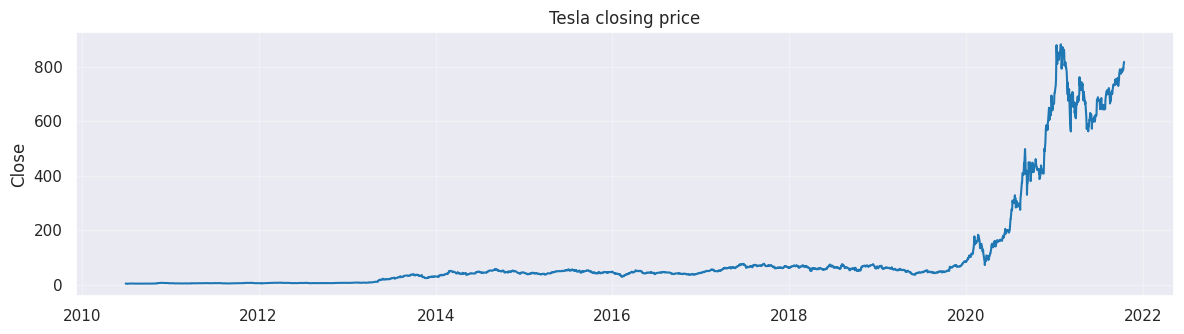

In [5]:
# Plot the closing price.
utils.plot_series(close, title="Tesla closing price", figsize=(12, 3.5))

**Guided usage**
- Compare the level in 2010 with the level in 2021
  - Observe a rise from about $3 to a peak of about $883 in January 2021
- Look at the size of the daily swings early and late in the history
  - Observe that the swings in dollars grow with the price
  - This matters for the prediction intervals in Part 6

**Implementation** `plot_series(series, *, title="", figsize=(12, 3.5))`
- Draws the values against the index as one line
- Adds the title, a label for the y axis, and a light grid

In [6]:
# Link the function to its source and list its interface.
hintros.print_obj_info(utils.plot_series)

- `plot_series(series: pandas.core.series.Series, *, title: str = '', figsize: Tuple[float, float] = (12, 3.5)) -> None`  
  Plot a time series as a line.

https://github.com/madhur2003/msml610_fall2026_kats_stock_price_forecasting/blob/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/class_project/msml610/Fall2026/projects/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/kats_utils.py#L984


## Cell 1.4: Hand the series to Kats

- Every Kats model takes a `TimeSeriesData`, with a `time` and a `value` column
- The wrappers in `kats_utils.py` do this conversion, so it happens inside each
  forecast call

In [7]:
# Convert the series and inspect the Kats object.
close_ts = utils.to_timeseries_data(close)
print("type =", type(close_ts).__name__)
print("points =", len(close_ts))
# Outcome: a `TimeSeriesData` with the same 2,946 points.

type = TimeSeriesData
points = 2946


# Part 2: Define the problem

## Cell 2.1: The forecasting task

- **Task**: forecast the closing price of the next 30 business days, about six
  weeks
- **Metric**: MAE and RMSE in dollars, plus the share of true prices that fall
  inside the 95% prediction interval
- **Baseline**: the naive forecast, the last price carried forward
  - Prices are close to a random walk, so a model that cannot beat this adds
    nothing
  - The column `MAE / naive MAE` below 1 means the model beats the baseline
- **Split**: chronological, with the last 30 business days as the test set
  - A random split would let the model train on days that come after the ones
    it is scored on

In [8]:
# Hold out the last 30 business days.
horizon = 30
train, test = utils.split_train_test(close, horizon)
# Outcome: the test window starts on 2021-09-03 and ends on 2021-10-14.

Train '2010-07-01' to '2021-09-02' (2916 points), test '2021-09-03' to '2021-10-14' (30 points)


## Cell 2.2: Is the series stationary?

- ARIMA needs a stationary series, and the differencing order `d` is the number
  of differences needed to get there
- The augmented Dickey-Fuller test has the null hypothesis that the series has a
  unit root, so a p-value below 0.05 means stationary

In [9]:
# Test the level and the first difference of the training set.
display(utils.check_stationarity(train))
# Outcome: the level is not stationary (p close to 1) and the first difference
# is (p near 0), so use `d=1`.

,adf_statistic,p_value,stationary_at_5pct
series,,,
level,1.287122,9.965359e-01,False
first difference,-10.088597,1.137886e-17,True


## Cell 2.3: Choose the ARIMA order on the training set

- With `d=1` fixed, try every `(p, q)` up to 2 and keep the one with the lowest
  AIC
- Only the training set is used, so the choice cannot see the test window

In [10]:
# Search the order by AIC.
arima_order = utils.select_arima_order(train)
print("arima_order =", arima_order)
# Outcome: the order (2, 1, 2).

Selected ARIMA order '(2, 1, 2)' with AIC '19991.6'
arima_order = (2, 1, 2)


# Part 3: Forecast

## Cell 3.1: Forecast with the three models

- `forecast_all()` fits the naive baseline, Kats ARIMA, and Kats Prophet on the
  training set and forecasts the 30 test days
- It sets the interval of every model to 95%
  - The Kats defaults differ: ARIMA's band is 95% and Prophet's is 80%, see
    `kats.API.ipynb`

In [11]:
# Forecast the test window with the three models.
forecasts = utils.forecast_all(train, horizon, arima_order=arima_order)
display(forecasts[utils.PROPHET].head(3))
# Outcome: a frame with `time`, `fcst`, `fcst_lower`, and `fcst_upper`, the same
# format for all three models.

,time,fcst,fcst_lower,fcst_upper
0,2021-09-03,765.709232,676.477097,854.120584
1,2021-09-06,769.216145,679.445853,865.488218
2,2021-09-07,770.274511,678.986028,858.195643


## Cell 3.2: Plot the forecasts with their intervals

**Goal**
- See each forecast and its 95% interval next to what really happened

**Description**
- Panels
  - `Naive`, `ARIMA`, `Prophet`: one panel per model, with the last 120 training
    days, the test prices, the forecast, and its interval

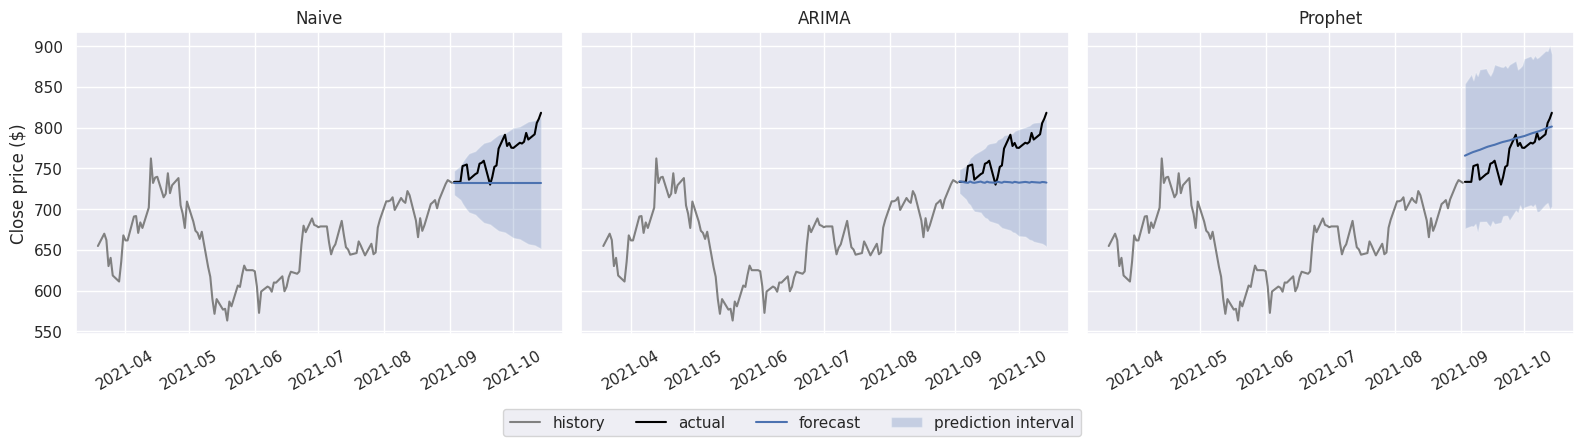

In [12]:
# Plot the three forecasts on a shared y axis.
utils.plot_forecasts(train, test, forecasts, num_history=120)

**Guided usage**
- Compare the forecast line with the black line of actual prices in each panel
  - Observe that the naive and ARIMA forecasts are nearly flat
  - Observe that Prophet continues the upward trend
- Compare the shape of the three intervals
  - Observe that the naive and ARIMA intervals fan out with the horizon
  - Observe that Prophet's interval is wide from the first day
- Check whether the actual prices stay inside each interval
  - Observe that the naive and ARIMA intervals miss the last days, when the
    price climbs, and that Prophet's covers the whole window

**Implementation** `plot_forecasts(train, test, forecasts, *, num_history=120,
ylabel="Close price ($)")`
- Draws the last `num_history` training points in each panel
- Draws the test values and each model's forecast with its interval
- Shares the y axis so the panels are comparable

In [13]:
# Link the function to its source and list its interface.
hintros.print_obj_info(utils.plot_forecasts)

- `plot_forecasts(train: pandas.core.series.Series, test: pandas.core.series.Series, forecasts: Dict[str, pandas.core.frame.DataFrame], *, num_history: int = 120, ylabel: str = 'Close price ($)', figsize: Tuple[float, float] = (16, 4.5)) -> None`  
  Plot history, actual test values, and each forecast with its interval.

https://github.com/madhur2003/msml610_fall2026_kats_stock_price_forecasting/blob/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/class_project/msml610/Fall2026/projects/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/kats_utils.py#L1006


## Cell 3.3: Compare the interval widths

- Intervals are comparable only at the same level, so check the widths after
  the alignment

In [14]:
# Compute the mean width of each 95% interval in dollars.
widths = pd.Series(
    {
        name: (f["fcst_upper"] - f["fcst_lower"]).mean()
        for name, f in forecasts.items()
    },
    name="mean interval width ($)",
)
display(widths.round(1).to_frame())
# Outcome: ARIMA ($107) and the naive baseline ($110) are close, since both widen
# like a random walk, and Prophet's interval is wider ($184).

,mean interval width ($)
Naive,110.1
ARIMA,106.9
Prophet,185.0


# Part 4: Evaluate on the test window

## Cell 4.1: Score the forecasts

In [15]:
# Score each forecast on the 30 held-out days.
scores = utils.evaluate_forecasts(test, forecasts)
display(scores.round(3))
# Outcome: Prophet has the lowest MAE ($19.6, about half of the naive MAE), while
# ARIMA is no better than the baseline (0.98). The Prophet interval covers all 30
# days, the other two cover 93% to 97%.

,MAE,RMSE,MAE / naive MAE,interval coverage
Prophet,19.585,23.153,0.555,1.000
ARIMA,34.652,41.923,0.982,0.933
Naive,35.303,42.485,1.000,0.967


## Cell 4.2: What the score does not say

- Prophet won this window, but one window is one draw
- Prophet extrapolates a trend, so it wins whenever the price keeps rising

In [16]:
# Compute the price change over the test window.
change = 100 * (test.iloc[-1] / train.iloc[-1] - 1)
print("price change over the test window = %.1f%%" % change)
# Outcome: the price rose 11.7%, a window that rewards a model that extrapolates
# the trend. Part 5 checks whether the win repeats.

price change over the test window = 11.7%


# Part 5: Does the result hold? A rolling backtest

## Cell 5.1: Walk back through eight windows

- The backtest cuts the last 240 business days into eight consecutive windows
  of 30 days
- At each origin, the models are refitted on the data before the window and
  scored on the window
- The ARIMA order is chosen on the data before the first window, so no window
  leaks into the choice

In [17]:
# Choose the order before the first window and run the backtest.
num_origins = 8
backtest_order = utils.select_arima_order(close.iloc[: -horizon * num_origins])
results = utils.rolling_origin_evaluation(
    close, horizon, num_origins=num_origins, arima_order=backtest_order
)
print("rows =", len(results))
# Outcome: 24 rows, one for each of the 8 origins and the 3 models.

Selected ARIMA order '(2, 1, 2)' with AIC '15446.3'


Origins:   0%|          | 0/8 [00:00<?, ?it/s]

Origins:  12%|█▎        | 1/8 [00:00<00:05,  1.18it/s]

Origins:  25%|██▌       | 2/8 [00:02<00:07,  1.31s/it]

Origins:  38%|███▊      | 3/8 [00:03<00:05,  1.19s/it]

Origins:  50%|█████     | 4/8 [00:05<00:05,  1.37s/it]

... (2 outputs left out)

Origins:  88%|████████▊ | 7/8 [00:09<00:01,  1.36s/it]

Origins: 100%|██████████| 8/8 [00:10<00:00,  1.38s/it]

Origins: 100%|██████████| 8/8 [00:10<00:00,  1.31s/it]

rows = 24


## Cell 5.2: The ratio to the baseline at each origin

In [18]:
# Show the MAE ratio of each model, with the price change of the window.
ratio = results.pivot(index="origin", columns="model", values="MAE / naive MAE")
ratio["price change (%)"] = results.groupby("origin")["price change (%)"].first()
display(ratio.round(2))
# Outcome: ARIMA stays at about 1 in every window. Prophet loses to the baseline
# in the first four windows (ratios from 1.75 to 3.08) and wins in the last four.

model,ARIMA,Naive,Prophet,price change (%)
origin,,,,
2020-11-12,1.00,1.0,1.75,60.72
2020-12-24,1.02,1.0,3.08,28.44
2021-02-04,1.02,1.0,2.01,-23.16
2021-03-18,0.97,1.0,2.96,3.65
2021-04-29,1.00,1.0,0.63,-9.88
2021-06-10,1.06,1.0,0.83,6.42
2021-07-22,0.99,1.0,0.79,12.80
2021-09-02,0.98,1.0,0.55,11.73


## Cell 5.3: Plot the ratio at each origin

**Goal**
- See at a glance in which windows each model beats the baseline

**Description**
- Panels
  - `MAE / naive MAE`: one line for ARIMA and one for Prophet over the forecast
    origins, with the baseline at 1

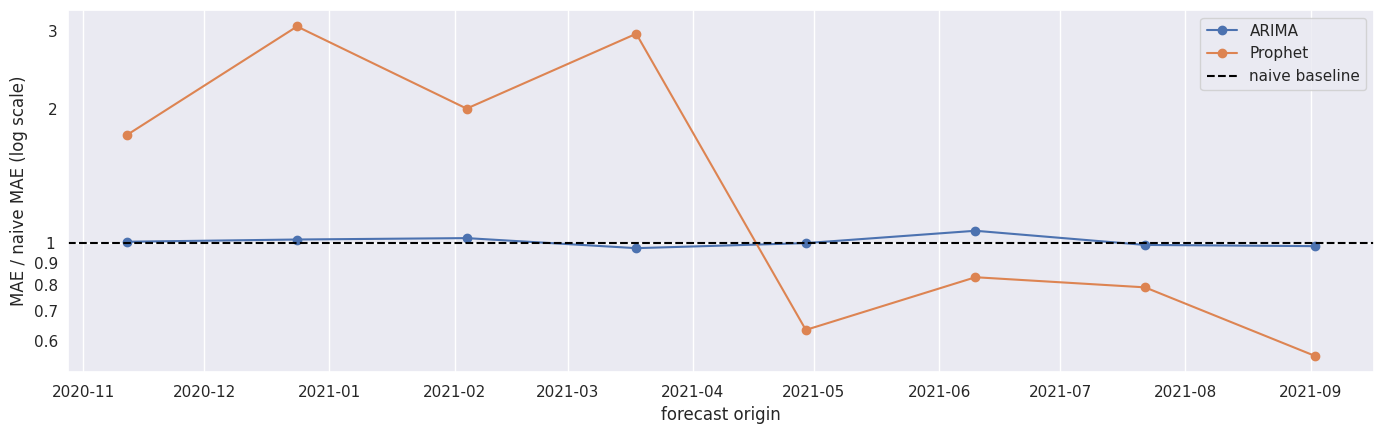

In [19]:
# Plot the ratio of each model at each origin.
utils.plot_rolling_evaluation(results)

**Guided usage**
- Look at where each line crosses the dashed baseline
  - Observe that ARIMA hugs the baseline in every window
  - Observe that Prophet sits above the baseline in the first four windows
    and below it in the last four
- Compare the size of the wins and the losses
  - Observe that the worst Prophet loss (about 3 times the baseline error) is
    larger than its best win (about half)

**Implementation** `plot_rolling_evaluation(results, *, figsize=(14, 4.5))`
- Plots the `MAE / naive MAE` of ARIMA and Prophet at each origin
- Draws the baseline as a dashed line at 1
- Uses a log scale, so a ratio of 2 and a ratio of 0.5 are equally far from 1

In [20]:
# Link the function to its source and list its interface.
hintros.print_obj_info(utils.plot_rolling_evaluation)

- `plot_rolling_evaluation(results: pandas.core.frame.DataFrame, *, figsize: Tuple[float, float] = (14, 4.5)) -> None`  
  Plot the MAE ratio to the naive baseline at each origin, one line a model.

https://github.com/madhur2003/msml610_fall2026_kats_stock_price_forecasting/blob/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/class_project/msml610/Fall2026/projects/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/kats_utils.py#L1051


## Cell 5.4: Summarize the backtest

In [21]:
# Summarize each model over the eight windows.
summary = utils.summarize_rolling_evaluation(results)
display(summary.round(2))
# Outcome: no model beats the baseline on average (ARIMA 1.01, Prophet 1.58).
# Each of the two beats it in 4 of 8 windows, and the intervals cover the true
# price in only 42% to 55% of the days, not 95%.

,mean MAE / naive MAE,windows beating naive (%),windows beating ARIMA (%),mean interval coverage
model,,,,
Naive,1.00,NaN,50.0,0.44
ARIMA,1.01,50.0,NaN,0.42
Prophet,1.58,50.0,50.0,0.55


# Part 6: Why the intervals miss, and the log fix

## Cell 6.1: A constant spread in dollars

- The naive and ARIMA intervals assume a fixed spread of the daily change in
  dollars, estimated on the whole training history
- Tesla's swings in dollars grew with its price, so a spread estimated on the
  cheap early years is too narrow for the recent windows
- The log of the price turns a swing proportional to the price into a constant
  spread, so the intervals can be modeled in logs and converted back

In [22]:
# Rerun the backtest on the log of the prices, scored in dollars.
log_results = utils.rolling_origin_evaluation(
    close,
    horizon,
    num_origins=num_origins,
    arima_order=backtest_order,
    log_scale=True,
)
log_summary = utils.summarize_rolling_evaluation(log_results)
display(log_summary.round(2))
# Outcome: the coverage of the naive and ARIMA intervals rises from 0.44 and 0.42
# to 0.86, close to the 95% target, while the MAE ratio is unchanged. Prophet
# gets worse (ratio 6.26): its log trend extrapolates the growth of the whole
# history.

Origins:   0%|          | 0/8 [00:00<?, ?it/s]

Origins:  12%|█▎        | 1/8 [00:00<00:06,  1.10it/s]

Origins:  25%|██▌       | 2/8 [00:02<00:06,  1.11s/it]

Origins:  38%|███▊      | 3/8 [00:03<00:07,  1.41s/it]

Origins:  50%|█████     | 4/8 [00:05<00:05,  1.41s/it]

Origins:  62%|██████▎   | 5/8 [00:06<00:04,  1.38s/it]

Origins:  75%|███████▌  | 6/8 [00:07<00:02,  1.32s/it]

Origins:  88%|████████▊ | 7/8 [00:08<00:01,  1.23s/it]

Origins: 100%|██████████| 8/8 [00:10<00:00,  1.28s/it]

Origins: 100%|██████████| 8/8 [00:10<00:00,  1.29s/it]

,mean MAE / naive MAE,windows beating naive (%),windows beating ARIMA (%),mean interval coverage
model,,,,
Naive,1.00,NaN,75.0,0.86
ARIMA,1.00,25.0,NaN,0.86
Prophet,6.26,12.5,12.5,0.26


## Cell 6.2: Compare the coverage before and after

In [23]:
# Put the coverage of the two runs side by side.
coverage = pd.DataFrame(
    {
        "dollars": summary["mean interval coverage"],
        "log prices": log_summary["mean interval coverage"],
    }
)
display(coverage.round(2))
# Outcome: the log fixes the intervals of the two simple models and not the
# Prophet point forecast, so the right scale depends on the model.

,dollars,log prices
model,,
Naive,0.44,0.86
ARIMA,0.42,0.86
Prophet,0.55,0.26


# Part 7: Bonus, a trading-volume feature with `MLARModel`

## Cell 7.1: Build the frame with the volume

- `MLARModel` is a gradient-boosted regressor over lagged values, and it can
  also read the lags of a covariate
- The volume varies by orders of magnitude, so use its log
- On a holiday the volume is the one of the previous trading day, as for the
  price

In [24]:
# Put the closing price and the log volume on the same grid.
log_volume = np.log(utils.to_business_day_series(prices, column="Volume"))
frame = pd.DataFrame({"Close": close, "log_volume": log_volume})
display(frame.tail(3))
# Outcome: two columns that share the business-day index.

Carried the last close forward over '103' non-trading business days


,Close,log_volume
2021-10-12,805.719971,16.907462
2021-10-13,811.080017,16.463110
2021-10-14,818.320007,16.317209


## Cell 7.2: Backtest `MLARModel` with and without the volume

- The windows are the same eight as in Part 5, so the ratios are comparable
- `MLARModel` gives no prediction interval, so only the MAE is scored

In [25]:
# Run both variants on the eight windows.
mlar_results = utils.rolling_origin_mlar(
    frame, horizon, num_origins=num_origins, covariate="log_volume"
)
mlar_ratio = mlar_results.pivot(
    index="origin", columns="model", values="MAE / naive MAE"
)
display(mlar_ratio.round(2))
# Outcome: the volume lowers the ratio in 7 of the 8 windows, most of all in the
# last two (from 1.96 and 1.83 to 0.75 and 0.80).

Origins:   0%|          | 0/8 [00:00<?, ?it/s]

Origins:  12%|█▎        | 1/8 [00:06<00:46,  6.67s/it]

Origins:  25%|██▌       | 2/8 [00:10<00:30,  5.16s/it]

Origins:  38%|███▊      | 3/8 [00:14<00:22,  4.53s/it]

Origins:  50%|█████     | 4/8 [00:18<00:17,  4.27s/it]

Origins:  62%|██████▎   | 5/8 [00:22<00:12,  4.21s/it]

Origins:  75%|███████▌  | 6/8 [00:26<00:08,  4.18s/it]

Origins:  88%|████████▊ | 7/8 [00:30<00:04,  4.15s/it]

Origins: 100%|██████████| 8/8 [00:34<00:00,  4.09s/it]

Origins: 100%|██████████| 8/8 [00:34<00:00,  4.34s/it]

model,MLAR,MLAR + log_volume
origin,,
2020-11-12,0.71,0.77
2020-12-24,0.44,0.29
2021-02-04,1.99,1.71
2021-03-18,1.78,1.43
2021-04-29,3.07,2.67
2021-06-10,0.74,0.68
2021-07-22,1.96,0.75
2021-09-02,1.83,0.80


## Cell 7.3: All the models in one table

In [26]:
# Collect the mean MAE ratio of every model over the eight windows.
mlar_mean = mlar_results.groupby("model")["MAE / naive MAE"].mean()
all_models = pd.concat([summary["mean MAE / naive MAE"], mlar_mean])
display(all_models.sort_values().round(2).to_frame("mean MAE / naive MAE"))
# Outcome: the volume brings `MLARModel` from 1.57 to 1.14, which is the best of
# the learned models, and still above the baseline (1.00).

,mean MAE / naive MAE
model,
Naive,1.00
ARIMA,1.01
MLAR + log_volume,1.14
MLAR,1.57
Prophet,1.58


# Part 8: Bonus, other intervals and other stocks

## Cell 8.1: Weekly and monthly prices

- `resample_series()` keeps the last price of each week or month, and drops the
  last period if the data stops before it ends
- The horizons cover a similar span: 30 days, 6 weeks, and 2 months
- The same functions run on any interval through the `freq` argument

In [27]:
# Backtest the three models on daily, weekly, and monthly prices.
intervals = {
    "daily": (utils.BUSINESS_DAY, 30),
    "weekly": (utils.WEEKLY, 6),
    "monthly": (utils.MONTHLY, 2),
}
interval_summaries = {}
for name, (freq, interval_horizon) in intervals.items():
    series = (
        close
        if freq == utils.BUSINESS_DAY
        else utils.resample_series(close, freq)
    )
    interval_summaries[name] = utils.backtest_prices(
        series, horizon=interval_horizon, num_origins=num_origins, freq=freq
    )
display(pd.concat(interval_summaries, names=["interval"]).round(2))
# Outcome: ARIMA is slightly better than the baseline on weekly prices (0.93) and
# worse on monthly ones (1.12). Prophet is worse than the baseline at every
# interval, and its intervals cover none of the monthly windows.

Selected ARIMA order '(2, 1, 2)' with AIC '15446.3'


Origins:   0%|          | 0/8 [00:00<?, ?it/s]

Origins:  12%|█▎        | 1/8 [00:00<00:06,  1.15it/s]

Origins:  25%|██▌       | 2/8 [00:02<00:07,  1.22s/it]

Origins:  38%|███▊      | 3/8 [00:03<00:05,  1.09s/it]

Origins:  50%|█████     | 4/8 [00:04<00:05,  1.28s/it]

... (26 outputs left out)

Origins:  88%|████████▊ | 7/8 [00:01<00:00,  5.80it/s]

Origins: 100%|██████████| 8/8 [00:01<00:00,  6.21it/s]

Origins: 100%|██████████| 8/8 [00:01<00:00,  6.26it/s]

mean MAE / naive MAE  windows beating naive (%)  windows beating ARIMA (%)  mean interval coverage
interval model                                                                                                      
daily    Naive                    1.00                        NaN                       50.0                    0.44
         ARIMA                    1.01                       50.0                        NaN                    0.42
         Prophet                  1.58                       50.0                       50.0                    0.54
weekly   Naive                    1.00                        NaN                       37.5                    0.48
         ARIMA                    0.93                       62.5                        NaN                    0.48
         Prophet                  2.08                       50.0                       50.0                    0.50
monthly  Naive                    1.00                        NaN                       62.5                    0.44
         ARIMA                    1.12                       37.5                        NaN                    0.44
         Prophet                  3.51                        0.0                        0.0                    0.00

## Cell 8.2: Other stocks

- The loop runs on every CSV in `data/`, and the ticker is the file name
- To add a stock, drop a file with the same columns in `data/`, for example
  `AAPL.csv` from Yahoo Finance, and rerun the cell
- This copy of the tutorial ships with Tesla only

In [28]:
# Backtest every stock found in the data directory.
data_dir = os.path.dirname(utils.get_default_data_path())
stock_summaries = {}
for ticker, path in utils.list_price_files(data_dir).items():
    stock_close = utils.to_business_day_series(utils.load_prices(path))
    stock_summaries[ticker] = utils.backtest_prices(
        stock_close, horizon=horizon, num_origins=num_origins
    )
display(pd.concat(stock_summaries, names=["ticker"]).round(2))
# Outcome: one block of three rows per stock. With Tesla only, it repeats the
# daily result of Cell 5.4.

Loaded '2843' rows from '2010-07-01' to '2021-10-14'
Carried the last close forward over '103' non-trading business days


Selected ARIMA order '(2, 1, 2)' with AIC '15446.3'


Origins:   0%|          | 0/8 [00:00<?, ?it/s]

Origins:  12%|█▎        | 1/8 [00:00<00:06,  1.10it/s]

Origins:  25%|██▌       | 2/8 [00:02<00:07,  1.22s/it]

Origins:  38%|███▊      | 3/8 [00:03<00:05,  1.15s/it]

... (3 outputs left out)

Origins:  88%|████████▊ | 7/8 [00:08<00:01,  1.22s/it]

Origins: 100%|██████████| 8/8 [00:09<00:00,  1.29s/it]

Origins: 100%|██████████| 8/8 [00:09<00:00,  1.22s/it]

mean MAE / naive MAE  windows beating naive (%)  windows beating ARIMA (%)  mean interval coverage
ticker model                                                                                                      
TSLA   Naive                    1.00                        NaN                       50.0                    0.44
       ARIMA                    1.01                       50.0                        NaN                    0.42
       Prophet                  1.58                       50.0                       50.0                    0.55

## Summary: What the example shows

- Kats gives the three forecasters the same inputs and outputs, so the whole
  comparison is one loop over a dictionary
- On the last 30 days, Prophet wins by a wide margin, and the rolling backtest
  shows that this is not a result to trust: no model beats the naive baseline
  on average over eight windows
- A single test window is one draw. Score several windows before choosing a
  model, and compare with the naive baseline, not only with each other
- Check the interval coverage, not only the point error. The 95% intervals
  covered 42% to 55% of the prices, because a spread in dollars is too narrow
  for a price that grew almost 200-fold. Modeling log prices restores most of the
  coverage for the simple models
- A volume feature helps `MLARModel` in 7 of 8 windows, which shows that extra
  information can matter, even when the model stays above the baseline
- Kats is unmaintained and needs the pinned environment of the Dockerfile, so
  treat it as a teaching tool for the common forecasting pattern